## Pregunta 3
##### De cada tipo ('type_1') de cada pokemon, cual es el que tiene la media de puntos de estadistica total ('base_stat_total') mas alta? 

Para responder esta pregunta hay que agrupar todos los Pokémon por su tipo principal y calcularemos la media cada uno.

In [5]:
# Importamos todas las librerias necesarias para mostrar y filtrar los datos correctamente
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Usamos seaborn para que le de una vista estetica a los datos que mostraremos
sns.set_theme(style="whitegrid")
%matplotlib inline

# Usando pandas leemos el csv y lo guardamos en una variable, para luego mostrar que se ha cargado correctamente
df = pd.read_csv('pokemon.csv')
print(f"Dataset carregat: {df.shape[0]} files i {df.shape[1]} columnes.")

Dataset carregat: 1025 files i 15 columnes.


In [7]:
# Agrupamos los pokemon por su tipo principal y calculamos la media de base_stat_total
media_por_tipo = df.groupby('type_1')['base_stat_total'].mean().round(1)

# Ordenamos de mayor a menor para que sea mas legible
media_por_tipo = media_por_tipo.sort_values(ascending=False).reset_index()
media_por_tipo.columns = ['Tipo', 'Media Base Stat Total']

# Mostramos la tabla resultado
media_por_tipo

,Tipo,Media Base Stat Total
0,Dragon,490.2
1,Steel,475.1
2,Dark,454.7
3,Psychic,446.7
4,Fire,446.2
5,Fighting,441.6
6,Rock,441.2
7,Ice,436.4
8,Electric,436.3
9,Flying,436.1


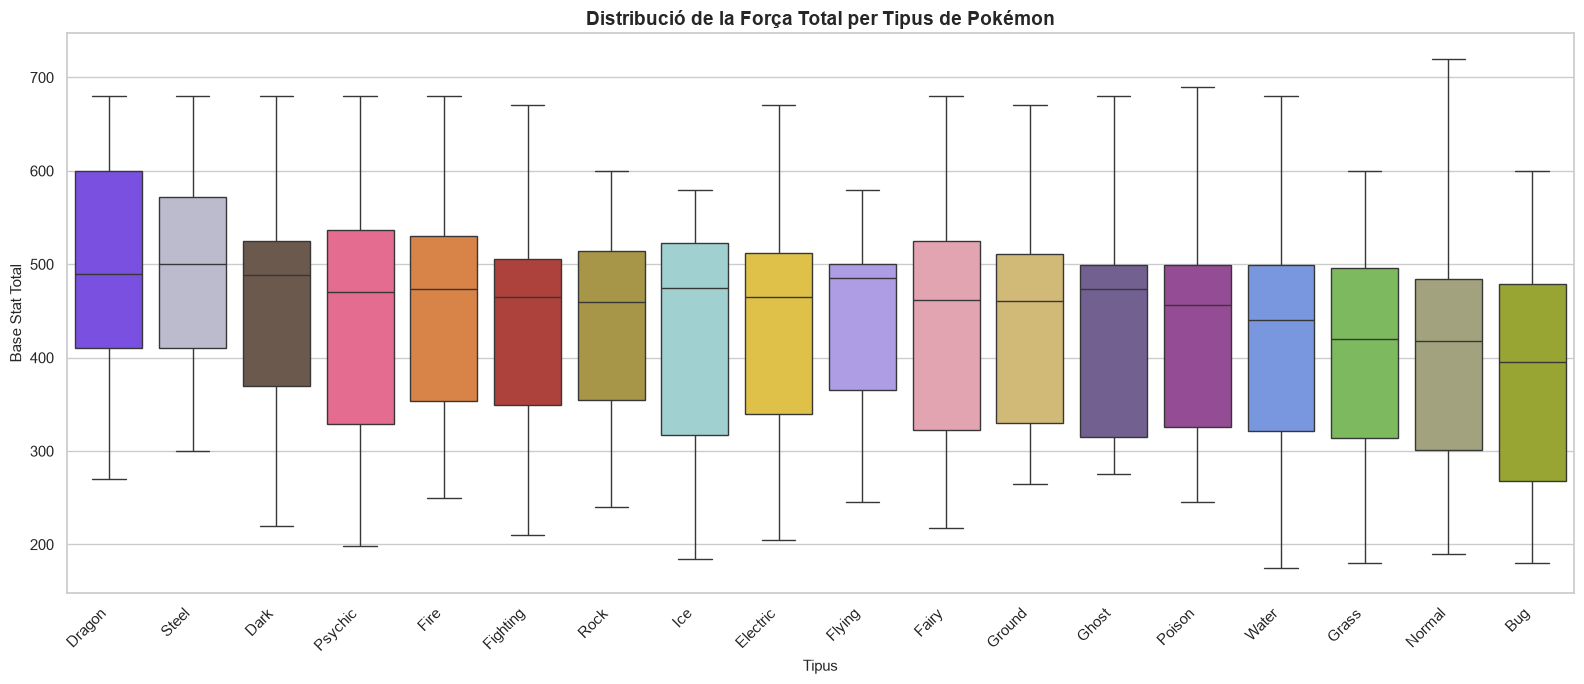

In [13]:
# Definimos los colores oficiales de cada tipo
colores_tipo = {
    'Dragon':   '#7038F8',
    'Steel':    '#B8B8D0',
    'Dark':     '#705848',
    'Psychic':  '#F85888',
    'Fire':     '#F08030',
    'Fighting': '#C03028',
    'Rock':     '#B8A038',
    'Ice':      '#98D8D8',
    'Electric': '#F8D030',
    'Flying':   '#A890F0',
    'Fairy':    '#EE99AC',
    'Ground':   '#E0C068',
    'Ghost':    '#705898',
    'Poison':   '#A040A0',
    'Water':    '#6890F0',
    'Grass':    '#78C850',
    'Normal':   '#A8A878',
    'Bug':      '#A8B820',
}

# Ordenamos los tipos de mayor a menor media para que el grafico sea mas legible
orden_tipos = media_por_tipo['Tipo'].tolist()

# Creamos la lista de colores en el mismo orden
colores = [colores_tipo[tipo] for tipo in orden_tipos]

# Definimos el tamaño del grafico
plt.figure(figsize=(16, 7))

# Creamos el boxplot con los tipos ordenados y sus colores oficiales
sns.boxplot(data=df, x='type_1', y='base_stat_total',
            order=orden_tipos, palette=colores_tipo,
            hue='type_1', legend=False)

# Añadimos titulo y etiquetas a los ejes
plt.title("Distribució de la Força Total per Tipus de Pokémon", fontsize=14, fontweight='bold')
plt.xlabel("Tipus", fontsize=11)
plt.ylabel("Base Stat Total", fontsize=11)

# Ajustamos los margenes y mostramos el grafico
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()